In [4]:
import seaborn as sns
sns.set_theme()

In [2]:
# import datasets
tips = sns.load_dataset('tips')
iris = sns.load_dataset('iris')

## Categorical Plots

### Categorical Scatter Plot

- Stripplot
- Swarmplot

### Categorical Distribution Plots

- Boxplot
- Violinplot

### Categorical Estimate Plot -> for central tendency

- Barplot
- Pointplot
- Countplot

### Figure level function -> `catplot`

<Axes: xlabel='total_bill', ylabel='tip'>

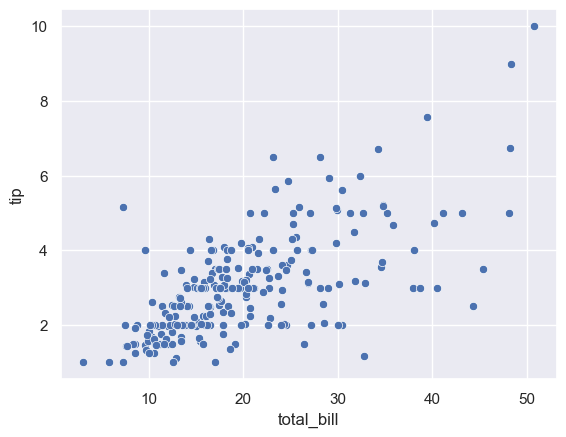

In [5]:
sns.scatterplot(data=tips, x='total_bill',y='tip')

<Axes: xlabel='day', ylabel='total_bill'>

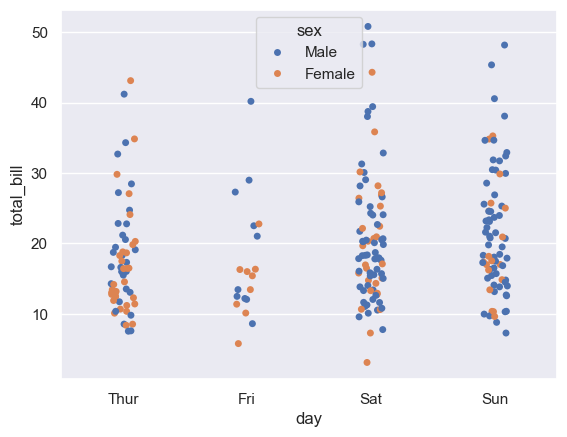

In [ ]:
# strip plot :  takes on caterorical and one numerical variable and shows the distribution of the numerical variable across the categories of the categorical variable
# axes level function
sns.stripplot(data=tips,x='day',y='total_bill' , hue='sex' ) ## by default jitter is True, so the points are jittered to avoid overlap

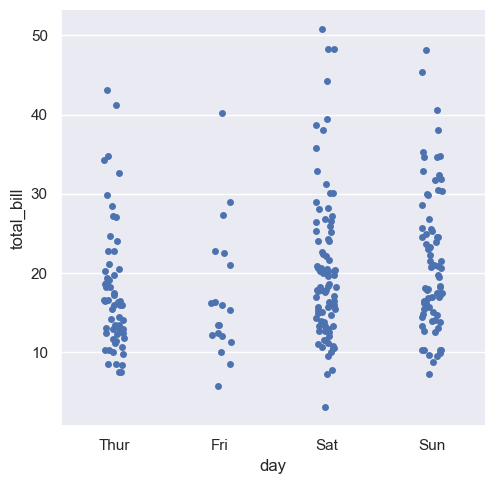

In [13]:
# using catplot
# figure level function
sns.catplot(
    kind="strip",
    data=tips,
    x="day",
    y="total_bill",
)

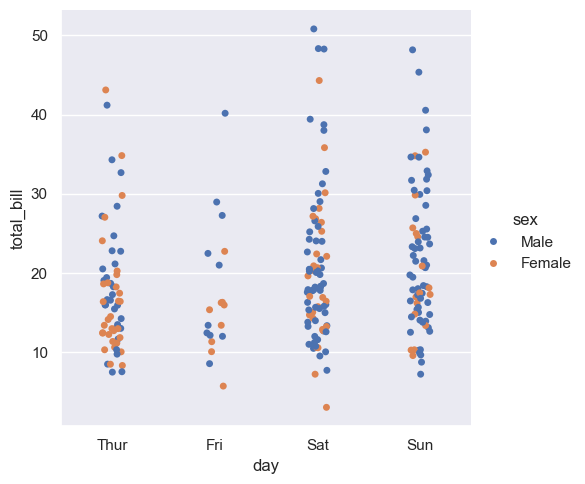

In [15]:
# jitter
sns.catplot(data=tips, x='day',y='total_bill',kind='strip',jitter=0.1,hue='sex')

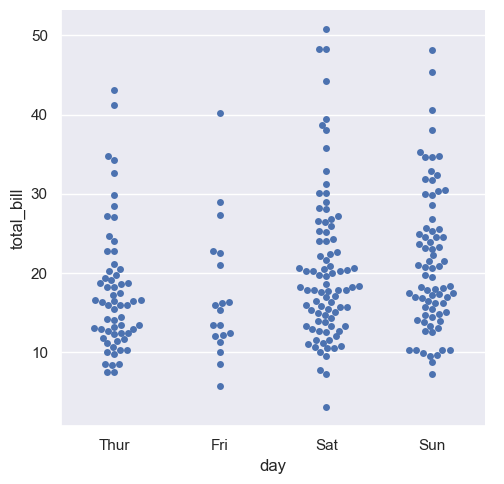

In [17]:
# swarmplot : this is similar to stripplot but the points are adjusted (swarm) so that they do not overlap. This is useful when you have a small number of observations and want to see all the data points. 
    # helps to understand the distribution of the data and identify any potential outliers or clusters within the data. It can also be used to compare the distributions of multiple groups within a categorical variable.
sns.catplot(data=tips, x='day',y='total_bill',kind='swarm')

<Axes: xlabel='day', ylabel='total_bill'>

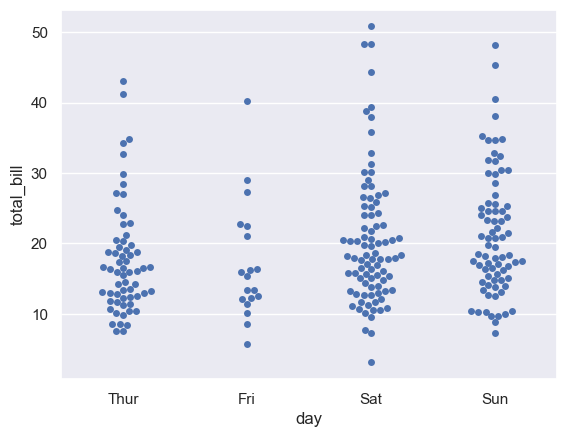

In [18]:
sns.swarmplot(data=tips, x='day',y='total_bill')

<Axes: xlabel='day', ylabel='total_bill'>

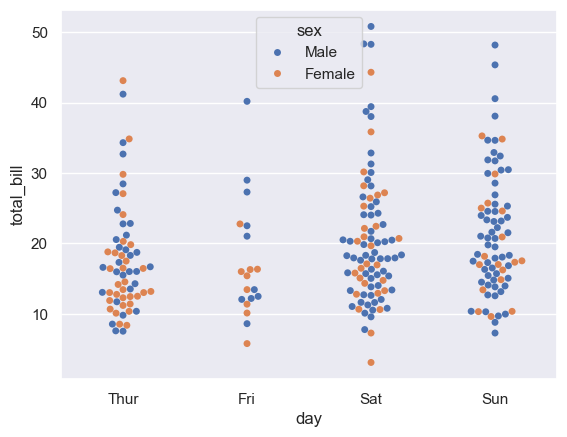

In [19]:
# hue
sns.swarmplot(data=tips, x='day',y='total_bill',hue='sex')

### Boxplot

A boxplot is a standardized way of displaying the distribution of data based on a five number summary (“minimum”, first quartile [Q1], median, third quartile [Q3] and “maximum”). It can tell you about your outliers and what their values are. Boxplots can also tell you if your data is symmetrical, how tightly your data is grouped and if and how your data is skewed.

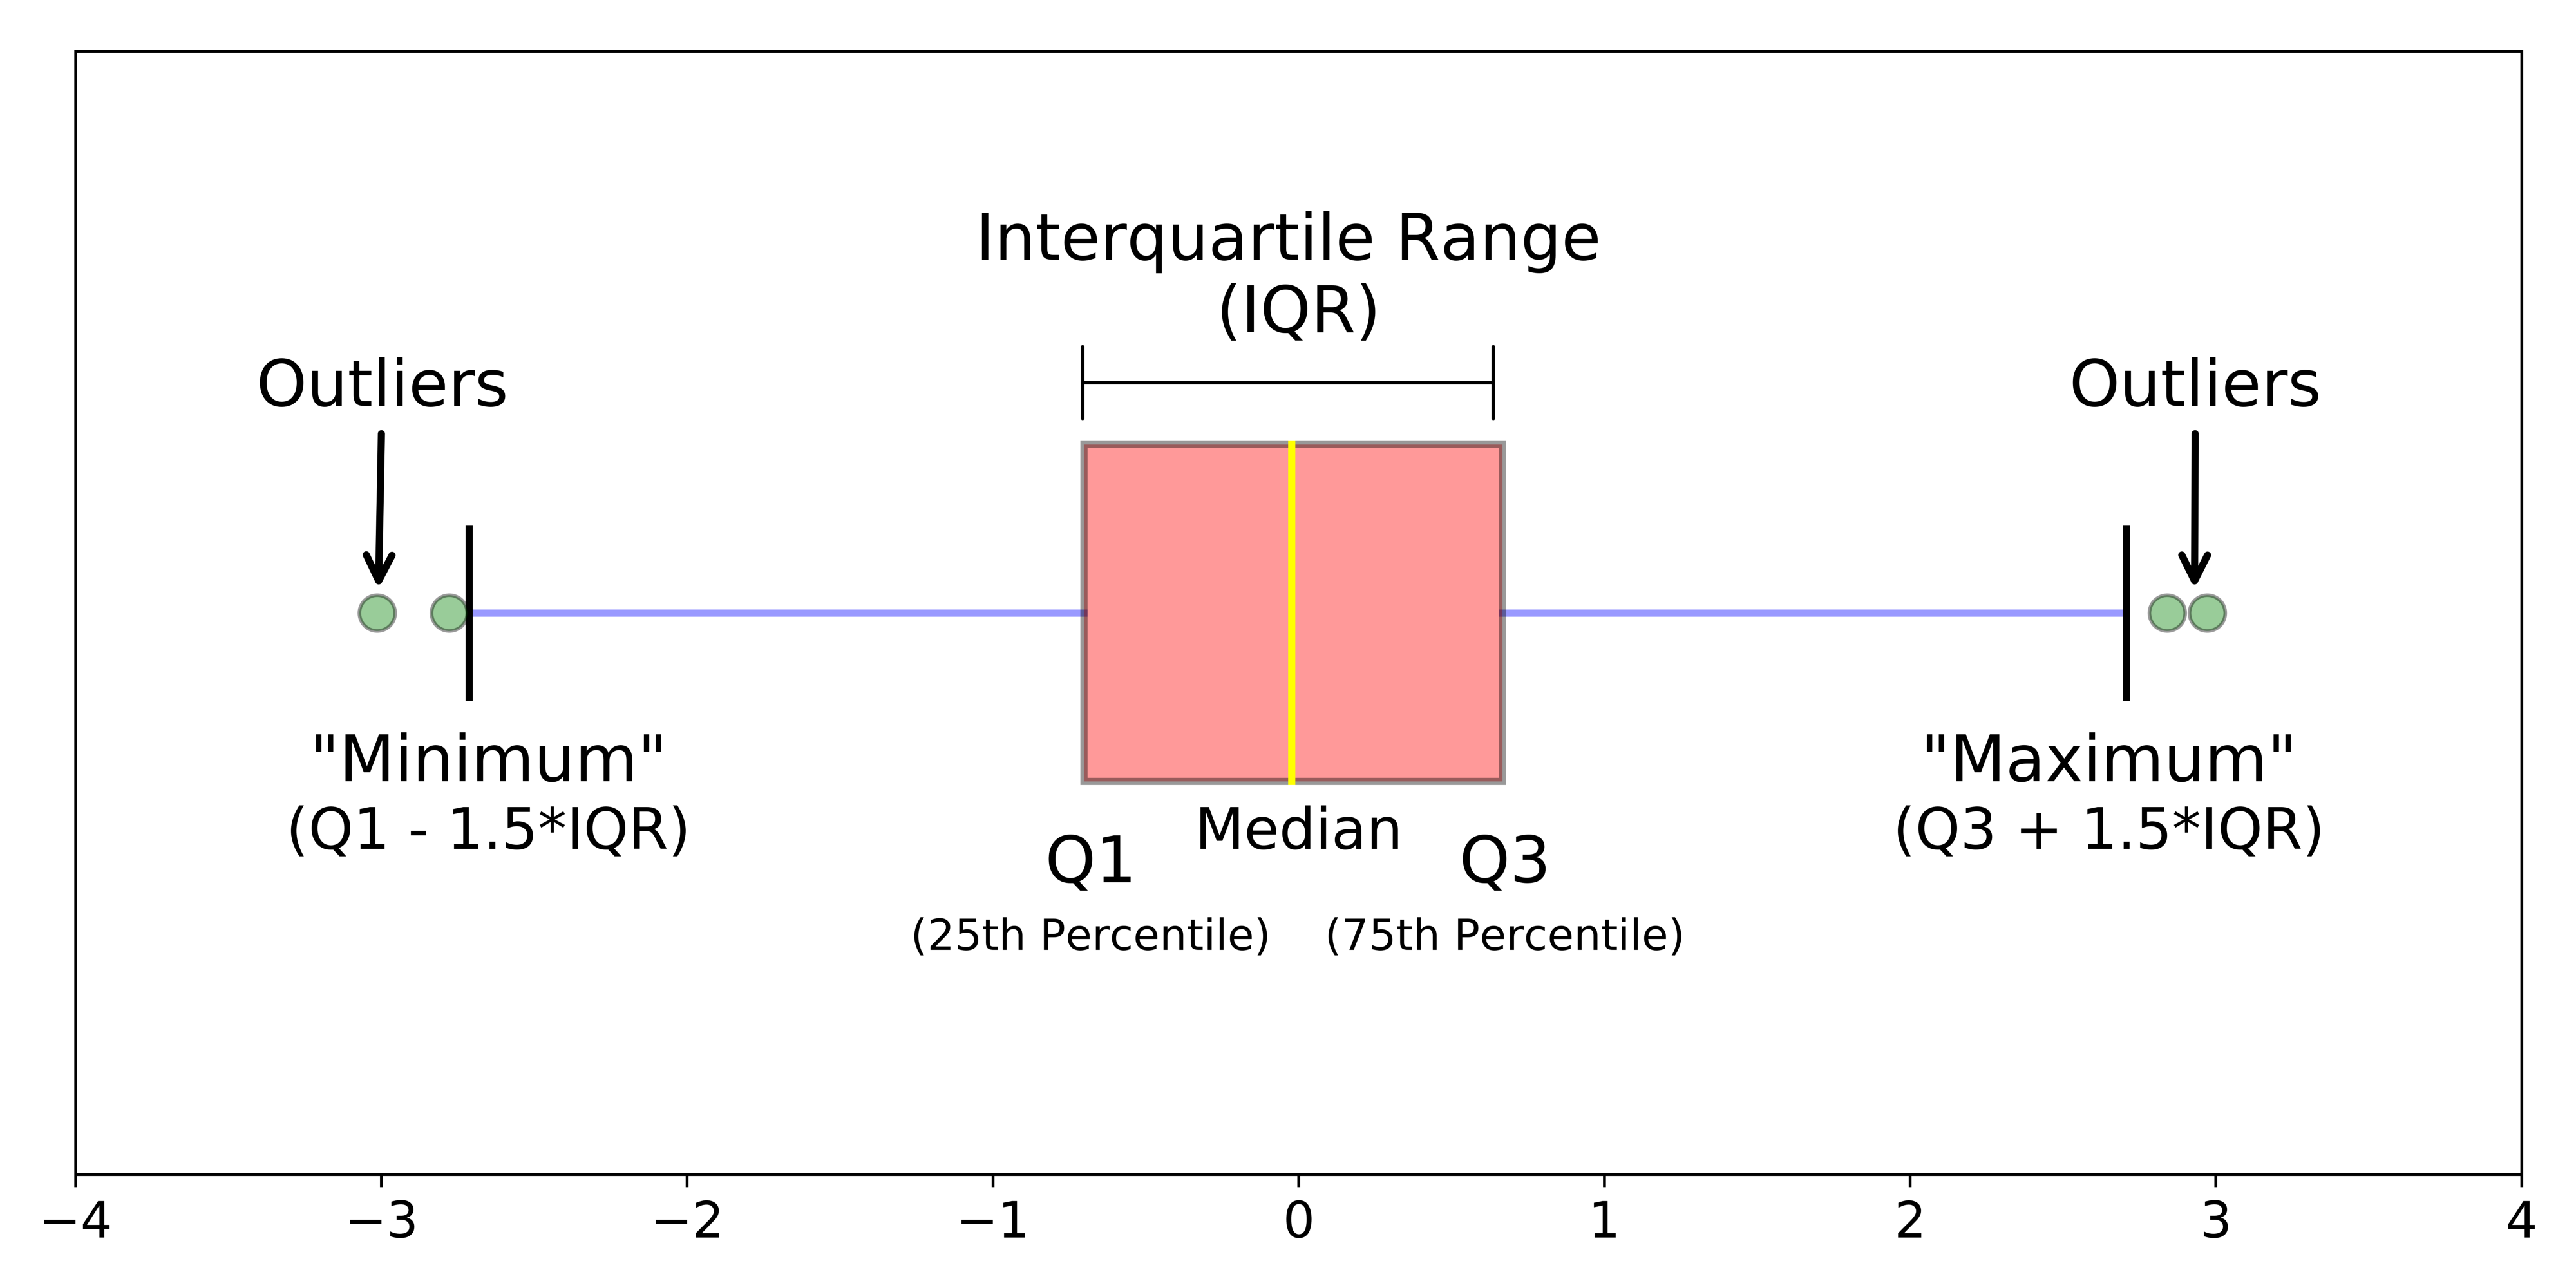

<Axes: xlabel='day', ylabel='total_bill'>

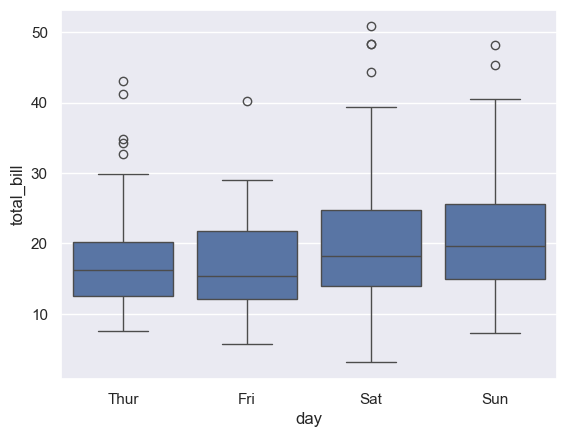

In [20]:
# Box plot
sns.boxplot(data=tips,x='day',y='total_bill')

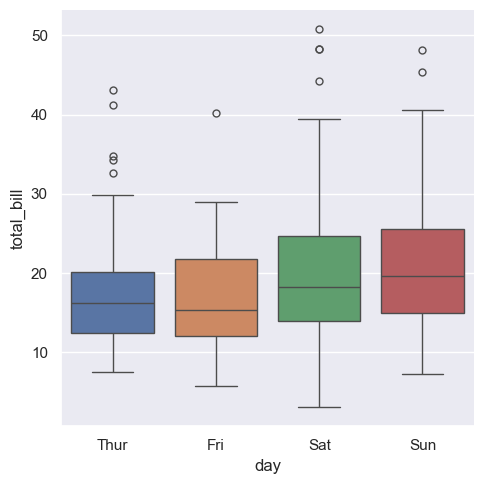

In [32]:
# Using catplot
sns.catplot(data=tips,x='day',y='total_bill',kind='box' , hue='day')

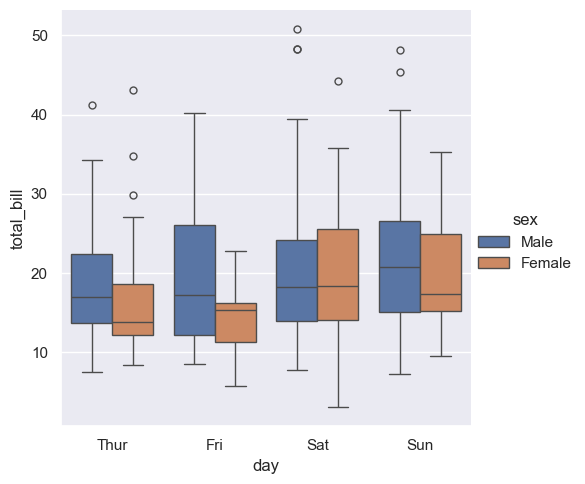

In [23]:
# hue
sns.catplot(kind="box" , data=tips,x='day',y='total_bill',hue='sex')

<Axes: ylabel='total_bill'>

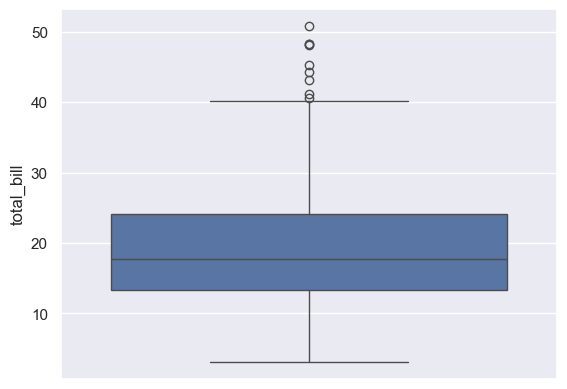

In [24]:
# single boxplot -> numerical col
sns.boxplot(data=tips,y='total_bill')

### Violinplot = (Boxplot + KDEplot)

<Axes: xlabel='day', ylabel='total_bill'>

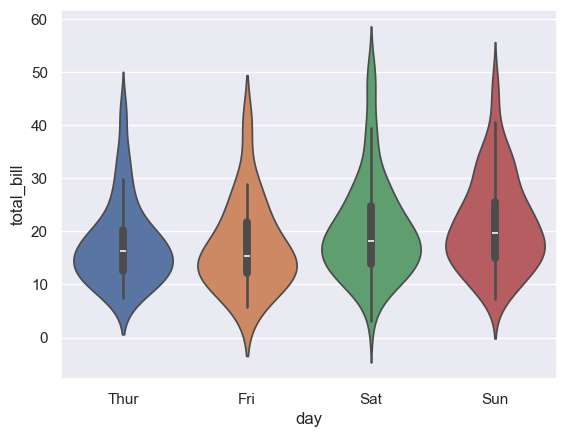

In [31]:
# violinplot
sns.violinplot(data=tips,x='day',y='total_bill' , hue="day")

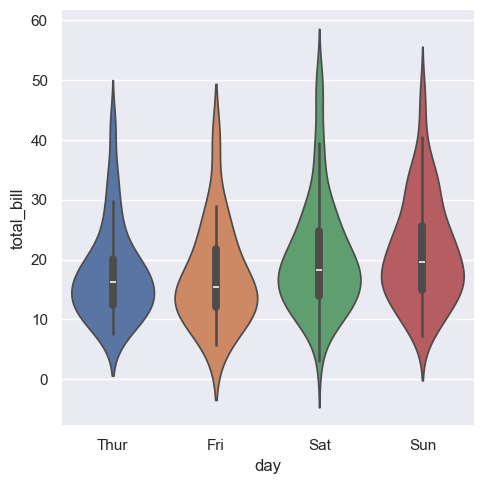

In [33]:
sns.catplot(data=tips,x='day',y='total_bill',kind='violin' , hue='day')

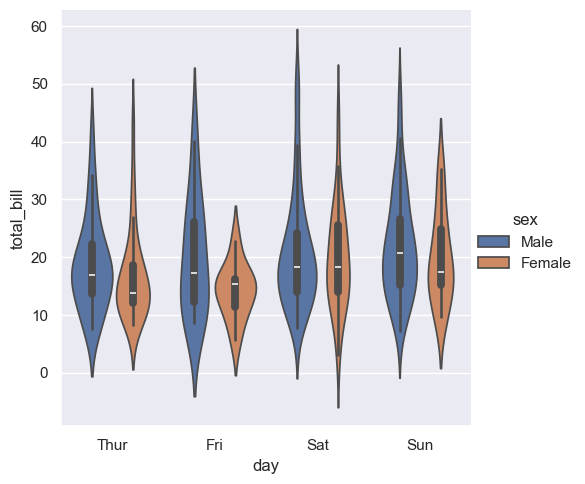

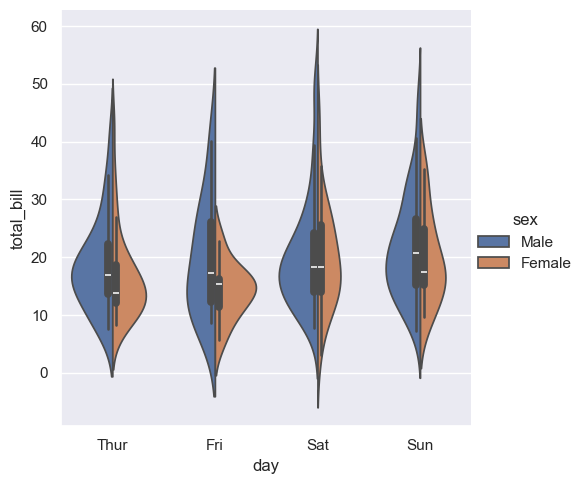

In [36]:
# hue
sns.catplot(data=tips,x='day',y='total_bill',kind='violin',hue='sex')
sns.catplot(data=tips,x='day',y='total_bill',kind='violin',hue='sex',split=True)

<Axes: xlabel='sex', ylabel='total_bill'>

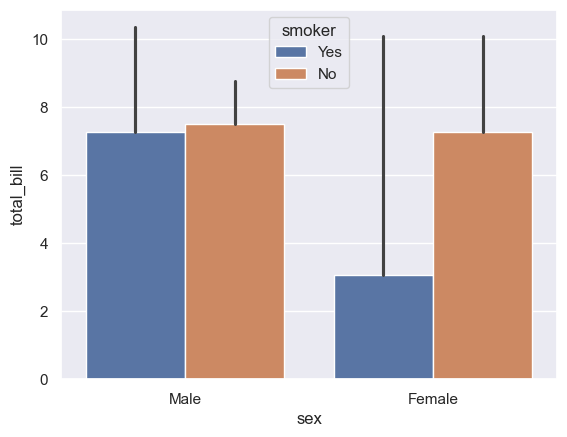

In [37]:
# barplot : with one categorical and one numerical variable, using some aggrigate function to show the relationship between the two variables. The height of the bar represents the value of the numerical variable for each category of the categorical variable.
# some issue with errorbar
import numpy as np
sns.barplot(data=tips, x='sex', y='total_bill',hue='smoker',estimator=np.min)

<Axes: xlabel='sex', ylabel='total_bill'>

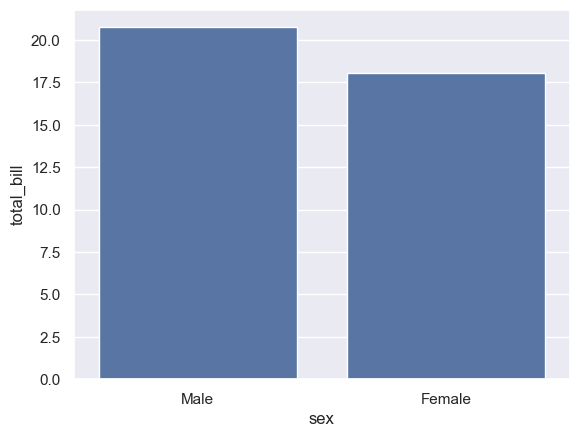

In [39]:
sns.barplot(data=tips, x='sex', y='total_bill',errorbar=None)

<Axes: xlabel='sex', ylabel='total_bill'>

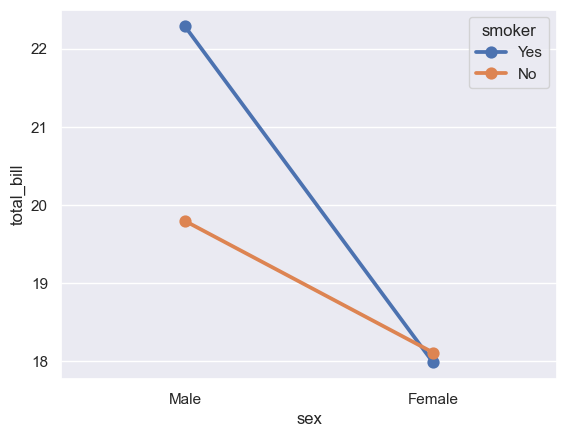

In [42]:
# point plot
sns.pointplot(data=tips, x='sex', y='total_bill',hue='smoker',errorbar=None)

When there are multiple observations in each category, it also uses bootstrapping to compute a confidence interval around the estimate, which is plotted using error bars

<Axes: xlabel='sex', ylabel='count'>

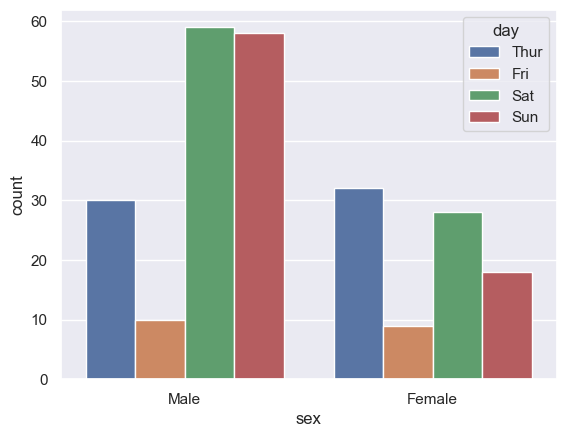

In [43]:
# countplot
sns.countplot(data=tips,x='sex',hue='day')

A special case for the bar plot is when you want to show the number of observations in each category rather than computing a statistic for a second variable. This is similar to a histogram over a categorical, rather than quantitative, variable

In [ ]:
# pointplot

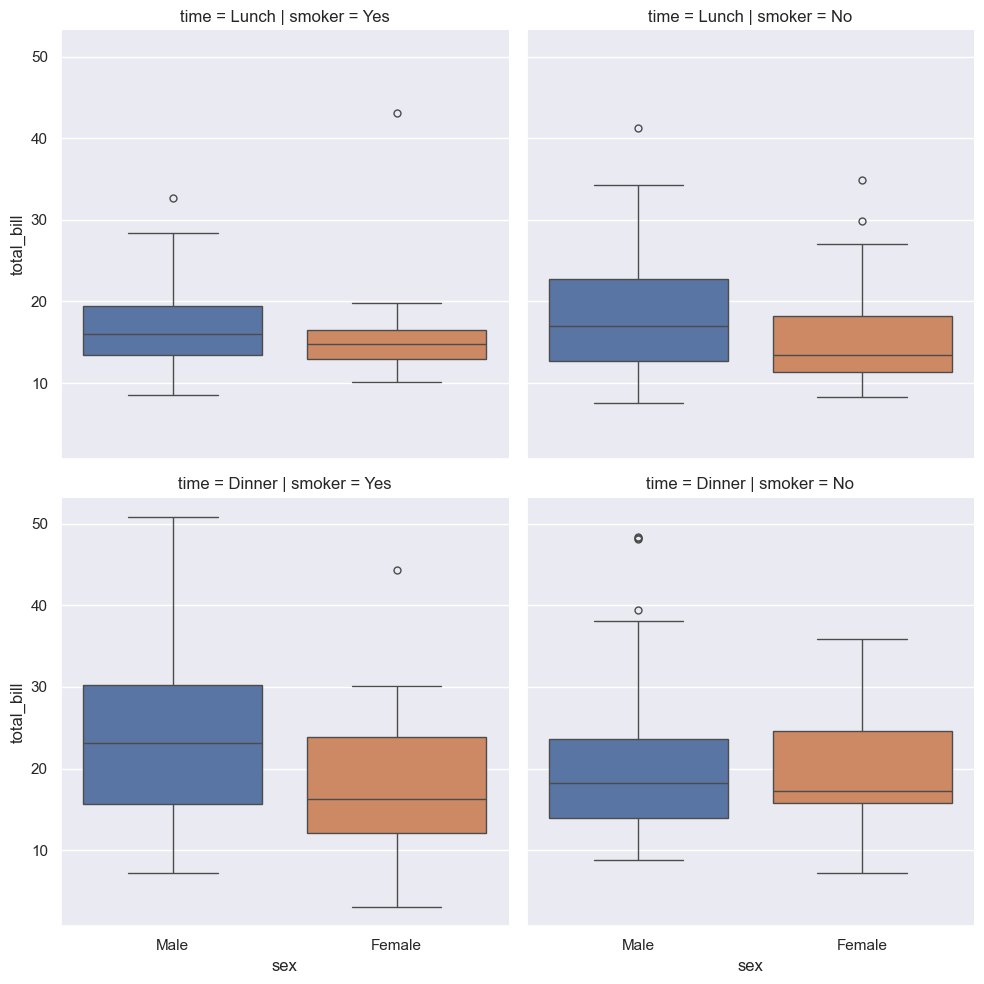

In [46]:
# faceting using catplot
sns.catplot(
    data=tips, x="sex", y="total_bill", hue="sex", col="smoker", kind="box", row="time"
)

### Regression Plots

- regplot
- lmplot

In the simplest invocation, both functions draw a scatterplot of two variables, x and y, and then fit the regression model y ~ x and plot the resulting regression line and a 95% confidence interval for that regression.

<Axes: xlabel='total_bill', ylabel='tip'>

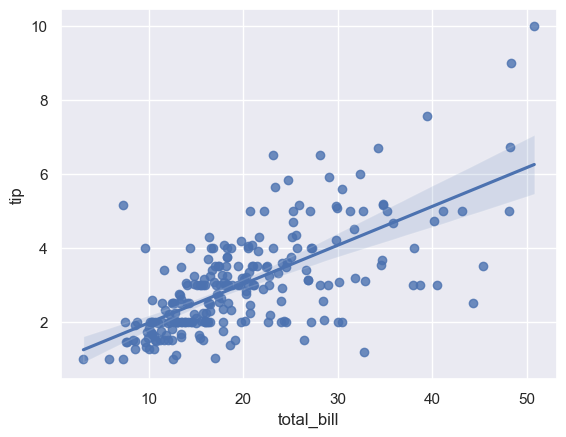

In [51]:
# axes level
# hue parameter is not available
sns.regplot(data=tips,x='total_bill',y='tip')

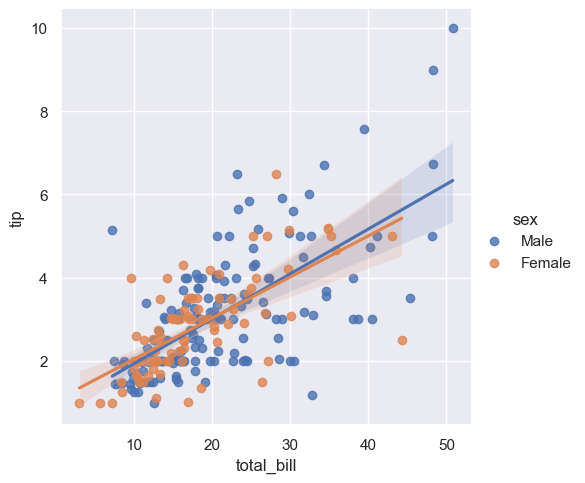

In [52]:
sns.lmplot(data=tips,x='total_bill',y='tip',hue='sex')

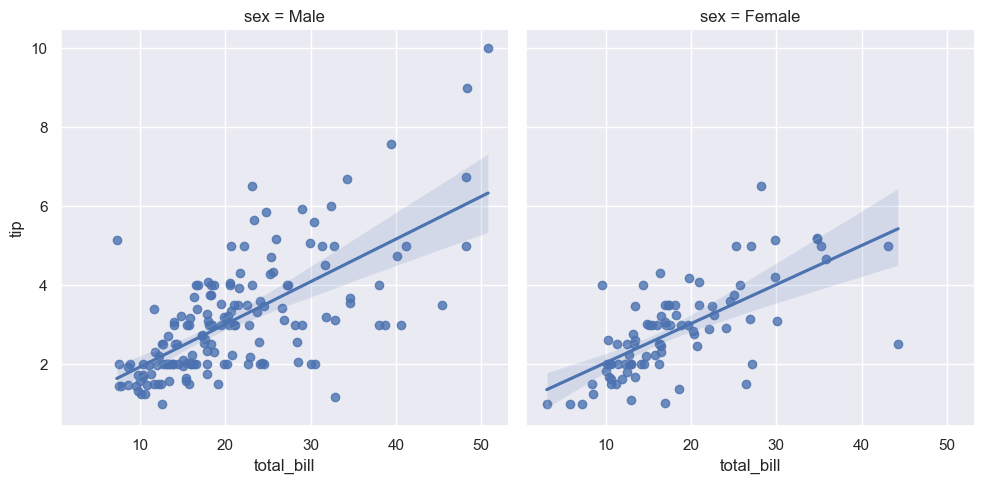

In [53]:
sns.lmplot(data=tips,x='total_bill',y='tip',col='sex')

<Axes: xlabel='total_bill', ylabel='tip'>

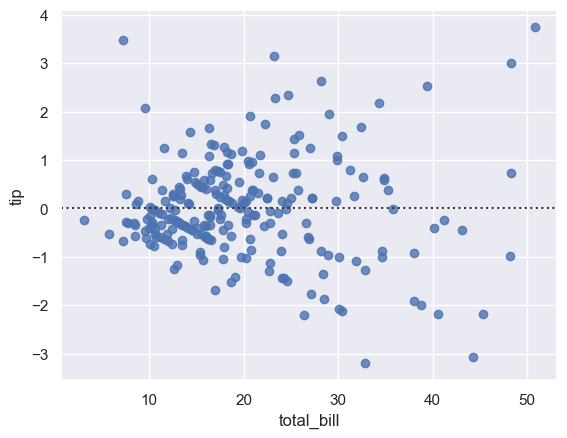

In [54]:
# residplot
sns.residplot(data=tips,x='total_bill',y='tip')

### A second way to plot Facet plots -> FacetGrid

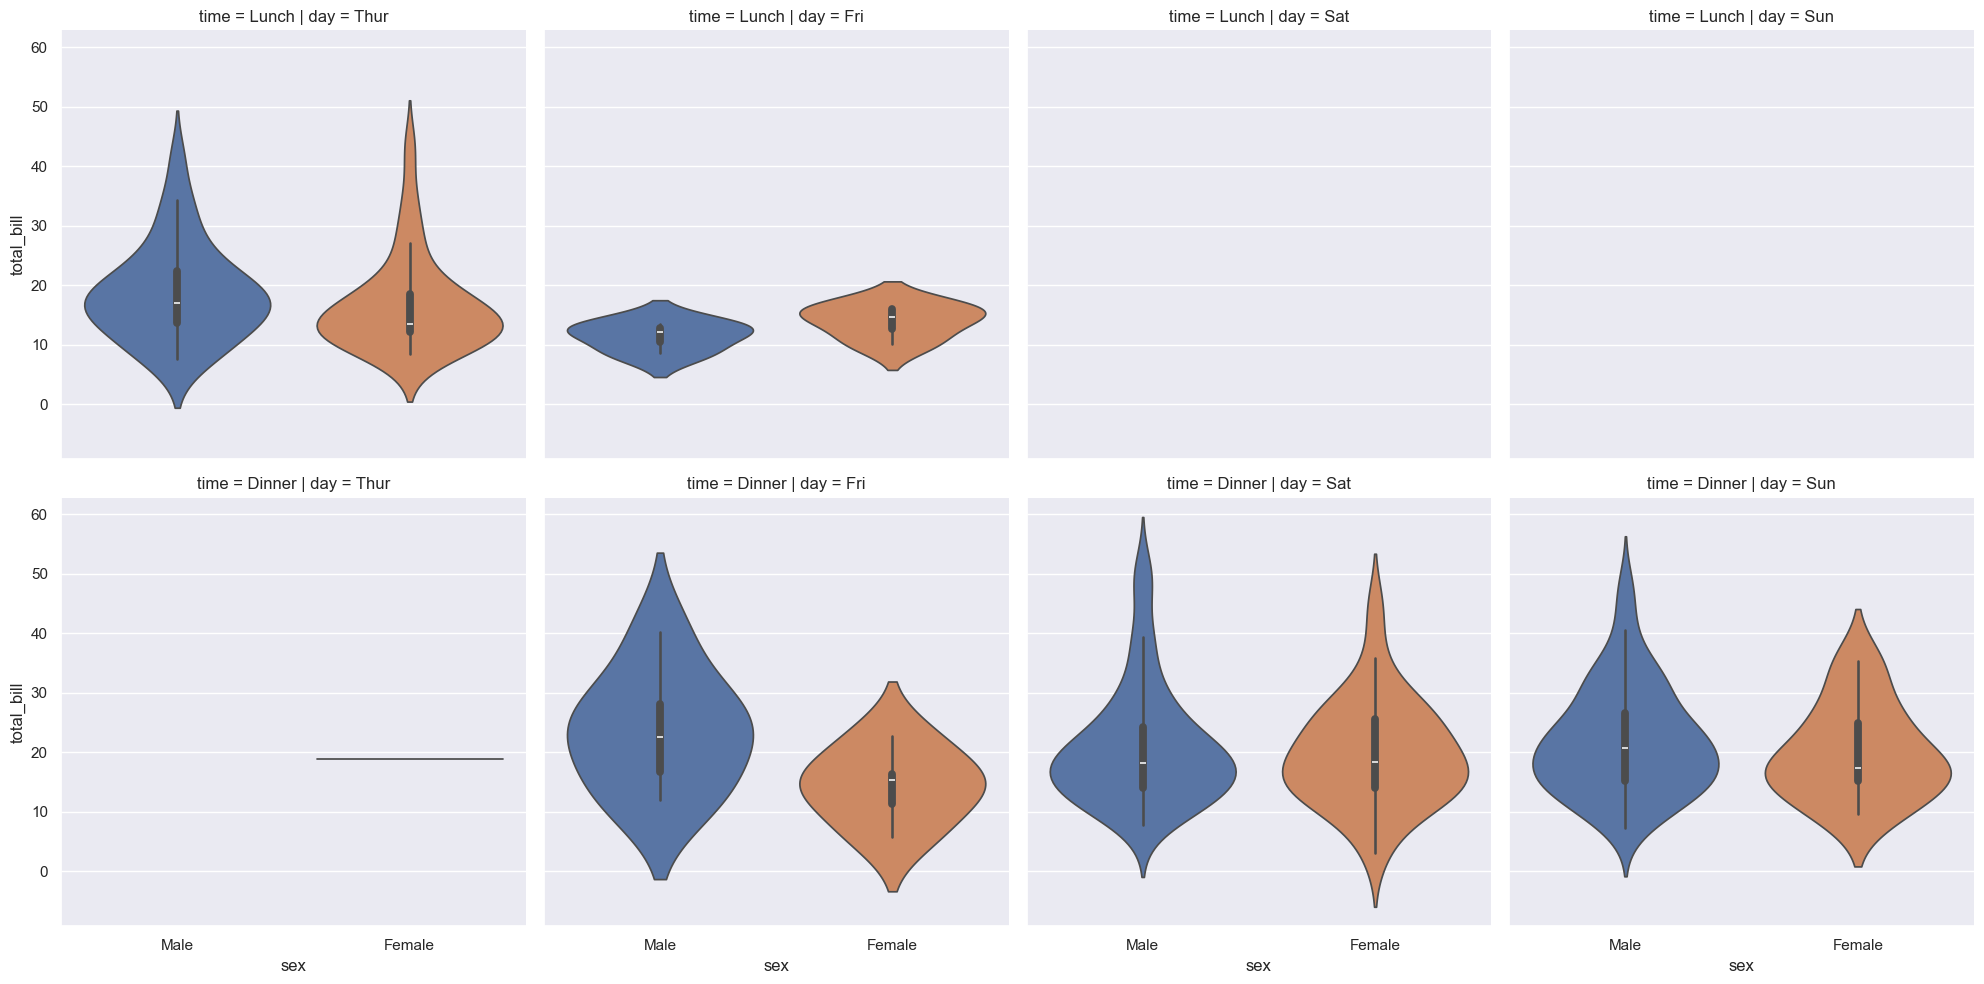

In [56]:
# figure level -> relplot -> displot -> catplot -> lmplot
sns.catplot(data=tips,x='sex',y='total_bill',kind='violin',col='day',row='time' , hue='sex')

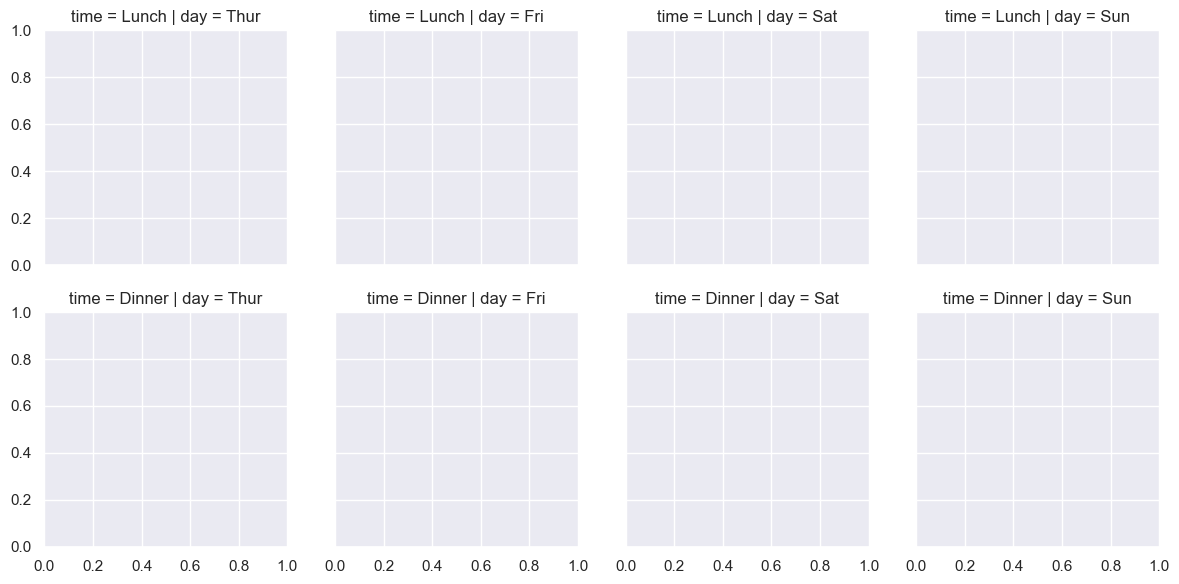

In [ ]:
g = sns.FacetGrid(data=tips,col='day',row='time',hue='smoker')


c:\Users\anish\anaconda3\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the boxplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


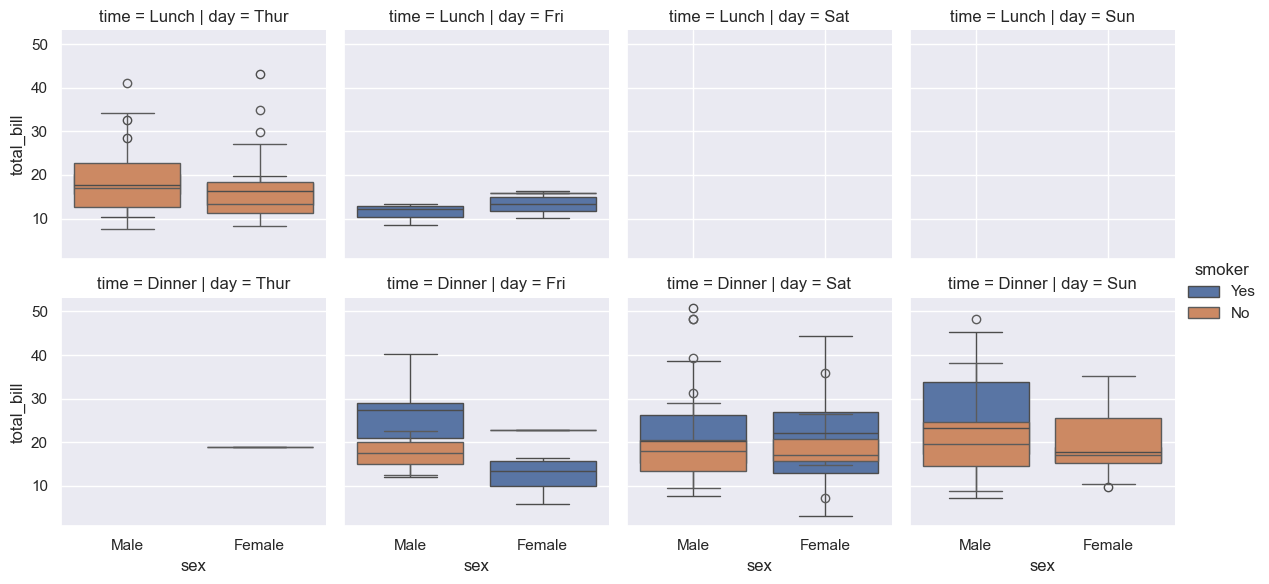

In [59]:
g = sns.FacetGrid(data=tips,col='day',row='time',hue='smoker')
g.map(sns.boxplot,'sex','total_bill')
g.add_legend()

### Plotting Pairwise Relationship (PairGrid Vs Pairplot)

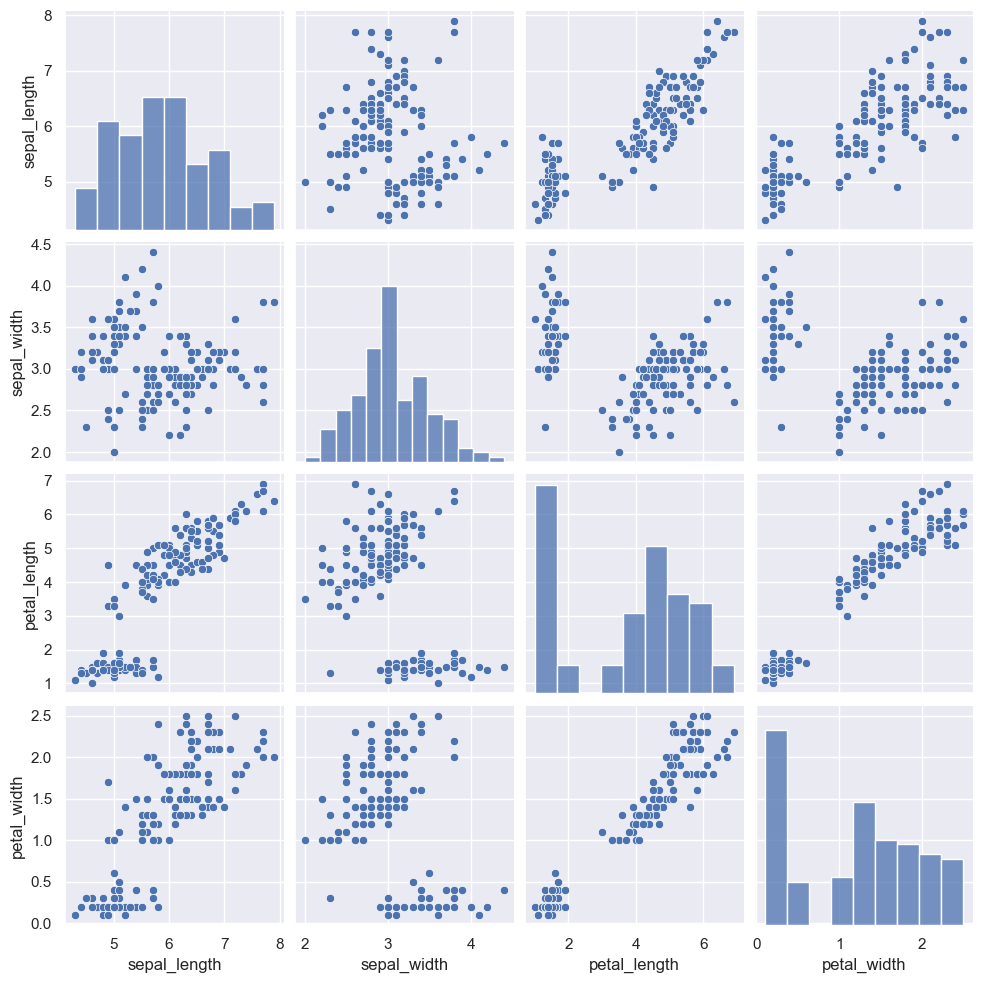

In [61]:
sns.pairplot(iris)

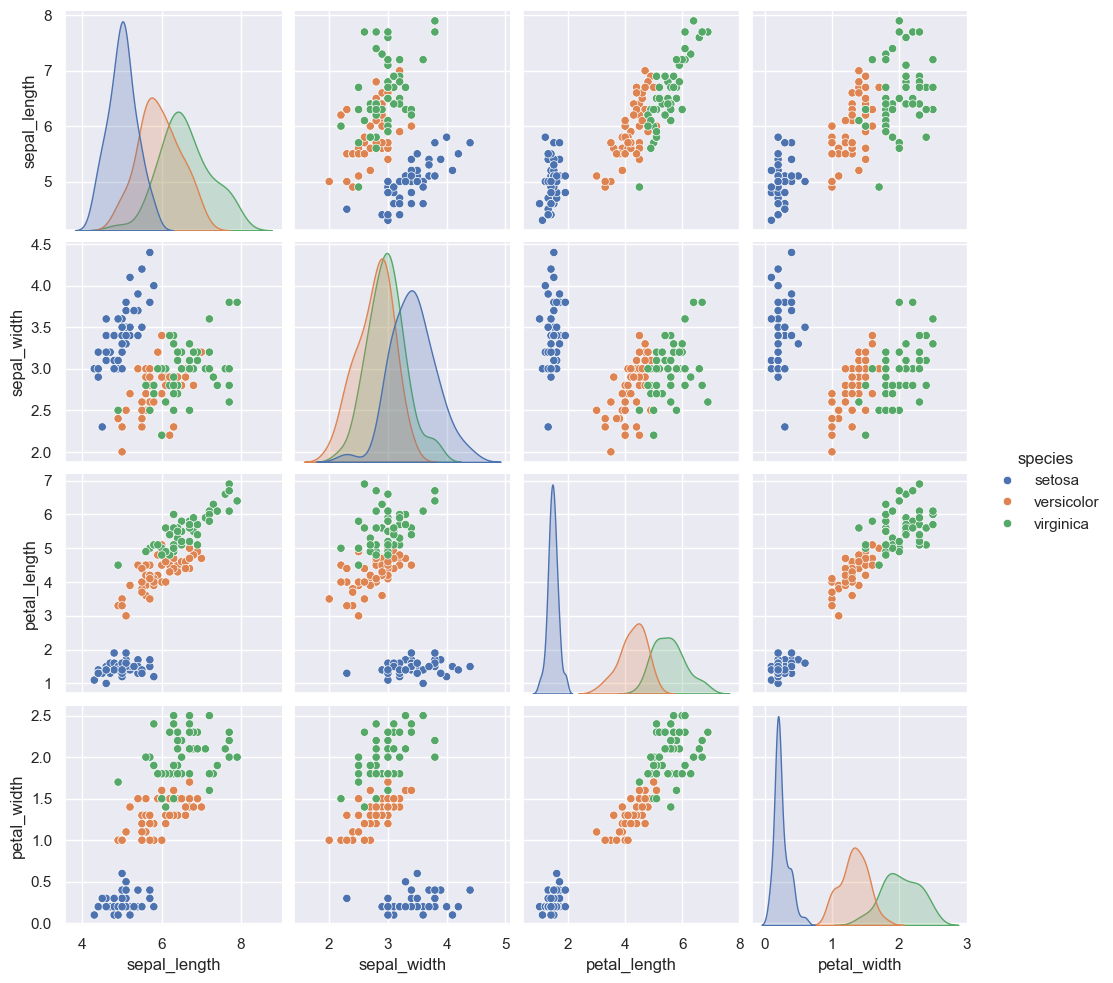

In [62]:
sns.pairplot(iris,hue='species')


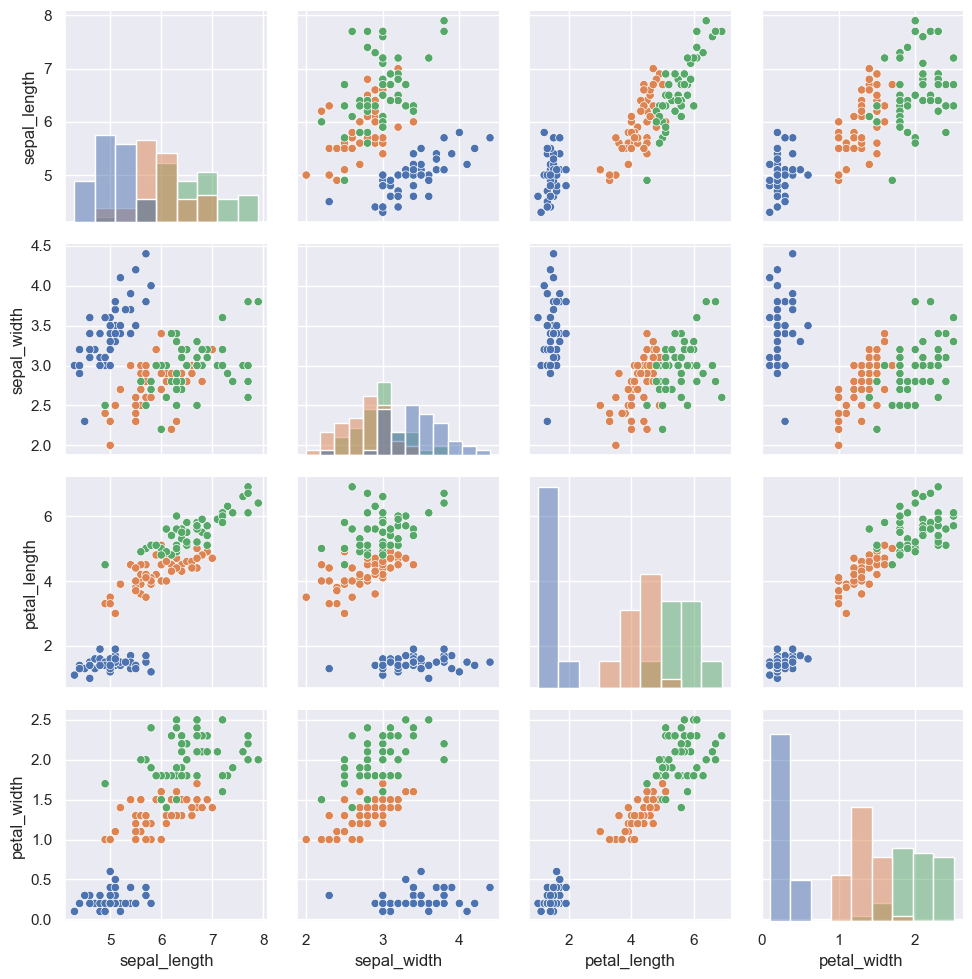

In [73]:
# pair grid
g = sns.PairGrid(data=iris,hue='species')
# g.map
g.map_offdiag(sns.scatterplot)
g.map_diag(sns.histplot)

## or for every plot in the grid if a same plot is to be used for all the plots in the grid use  Example ::: `.map(sns.scatterplot)`

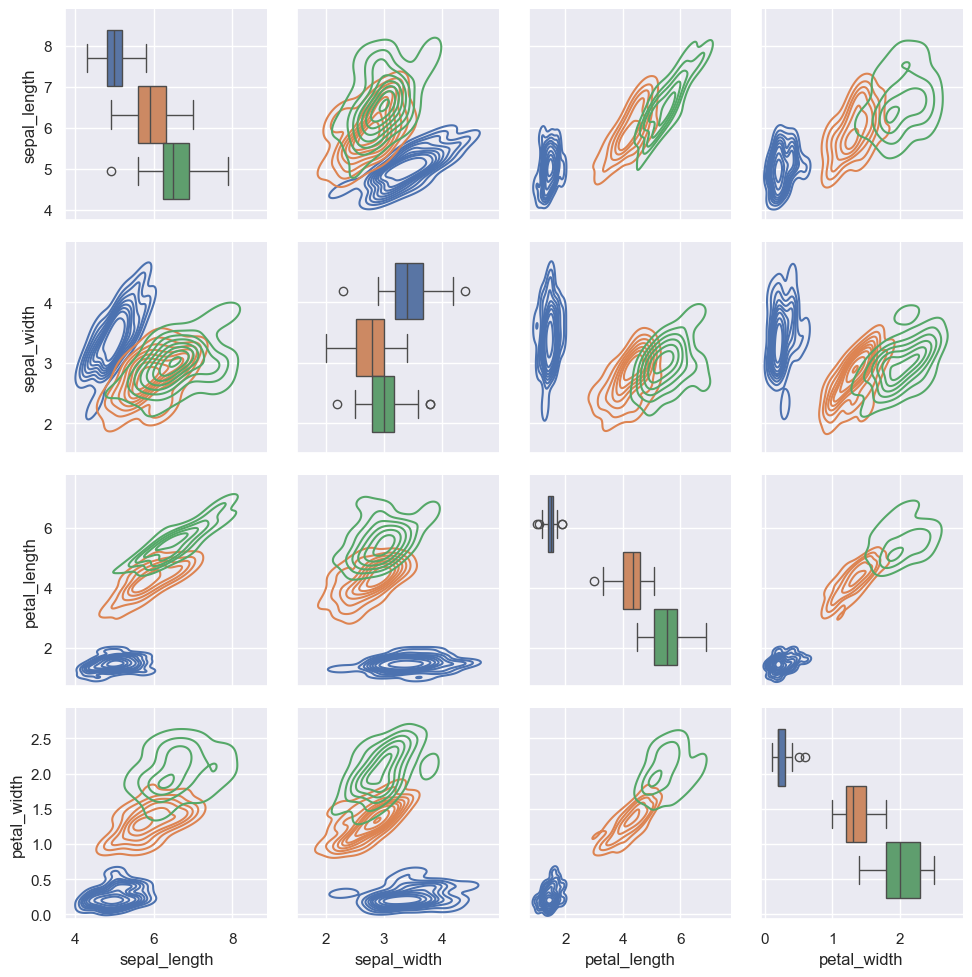

In [66]:
# map_diag -> map_offdiag
g = sns.PairGrid(data=iris,hue='species')
g.map_diag(sns.boxplot)
g.map_offdiag(sns.kdeplot)

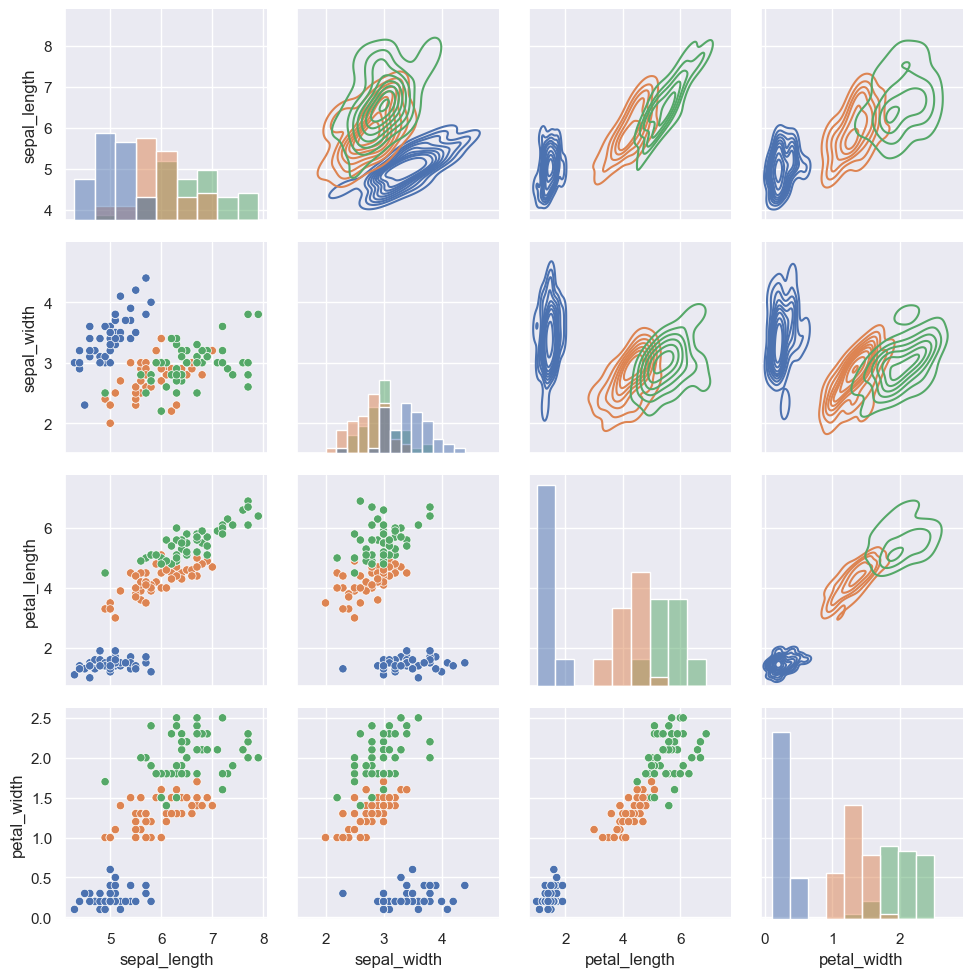

In [67]:
# map_diag -> map_upper -> map_lower
g = sns.PairGrid(data=iris,hue='species')
g.map_diag(sns.histplot)
g.map_upper(sns.kdeplot)
g.map_lower(sns.scatterplot)

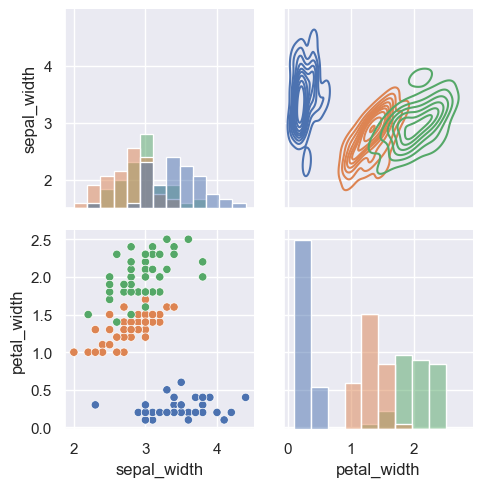

In [68]:
# vars
g = sns.PairGrid(data=iris,hue='species',vars=['sepal_width','petal_width'])
g.map_diag(sns.histplot)
g.map_upper(sns.kdeplot)
g.map_lower(sns.scatterplot)

### JointGrid Vs Jointplot
-  Joint plot is a plot  , here you can plot the relationship between two variables along with their marginal distributions. It combines scatter plots or hexbin plots with histograms or KDE plots on the axes.

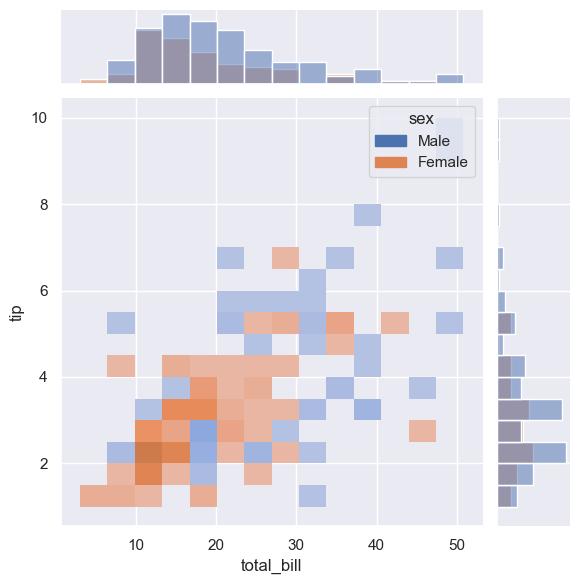

In [69]:
sns.jointplot(data=tips,x='total_bill',y='tip',kind='hist',hue='sex')

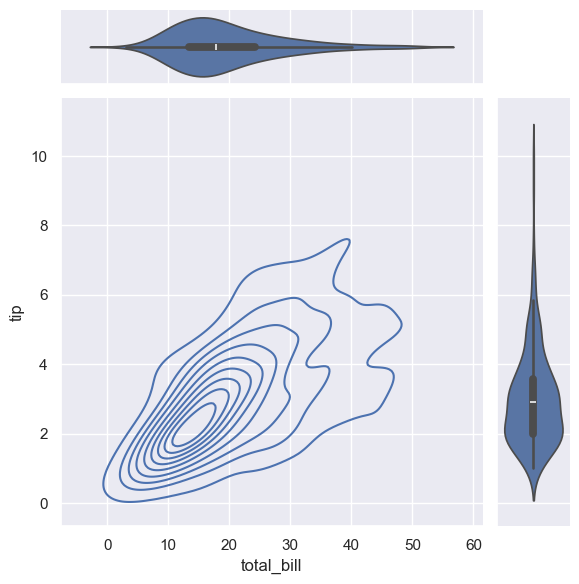

In [70]:
g = sns.JointGrid(data=tips,x='total_bill',y='tip')
g.plot(sns.kdeplot,sns.violinplot)

### Utility Functions

In [ ]:
# get dataset names
sns.get_dataset_names()

['anagrams',
 'anscombe',
 'attention',
 'brain_networks',
 'car_crashes',
 'diamonds',
 'dots',
 'dowjones',
 'exercise',
 'flights',
 'fmri',
 'geyser',
 'glue',
 'healthexp',
 'iris',
 'mpg',
 'penguins',
 'planets',
 'seaice',
 'taxis',
 'tips',
 'titanic']

In [ ]:
# load dataset
sns.load_dataset('planets')

,method,number,orbital_period,mass,distance,year
0,Radial Velocity,1,269.300000,7.10,77.40,2006
1,Radial Velocity,1,874.774000,2.21,56.95,2008
2,Radial Velocity,1,763.000000,2.60,19.84,2011
3,Radial Velocity,1,326.030000,19.40,110.62,2007
4,Radial Velocity,1,516.220000,10.50,119.47,2009
...,...,...,...,...,...,...
1030,Transit,1,3.941507,NaN,172.00,2006
1031,Transit,1,2.615864,NaN,148.00,2007
1032,Transit,1,3.191524,NaN,174.00,2007
1033,Transit,1,4.125083,NaN,293.00,2008
